# Introduction to Langgraph

Langgraph is a framework that is used to build stateful workflows and agents using graphs.

Low-level-Orchestration framework

There are 2 ways of learning Langgraph
- Graph API
- Functional API 

We will start with Graph API, since it is simple and easy to start with 

## Graph
Here Graph refers to the workflows of the agent.

### Components of Langgraph
- Edge
- Node
- State

#### Edge 
Edge is the direction of execution, it shows the workflow

#### Node 
Node is usually a function, where an operation is performed or a task is done or implemented

#### State 
State is the data that flows through the whole graph.
- it consists of Data that is accessible all over the graph


<B>This type of graph is also called as Stateful Graphs, because the context of the state is maintained over the whole graph at every node</B>

In [55]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')
os.environ['TAVILY_API_KEY']=os.getenv('TAVILY_API_KEY')


In the below cell,
- <b>Annotated</b> is used so that we can add extra metadata to the type, like telling the type to append ,not overwrite and all those
- <b>TypedDict</b> is just a plain dictionary
- <b>StateGraph</b> is used to build the stateGraph.  <b>START</b>, <b>END</b> are just starting and ending nodes
- <b>add_messages</b> this is called a <b>reducer</b>. It means, that we will only append to the type and not overwriting. 


In [56]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [57]:
from langchain.chat_models import init_chat_model

llm=init_chat_model(
    model="groq:llama-3.1-8b-instant"
)

##### State representation
States is made typeddict, so that the schema and the merging is known and done easily\
messages into list, because it consists of different messages like HumanMessages, Ai Messages and all that just need to be added into the list, since we have to store them all. 
So we use add_messages as reducers.

In [58]:
class State(TypedDict):
    # the add_messages in the annotation will define how the model will be updated
    messages:Annotated[list,add_messages]


##### StateGraph(State)
This tells the graph to use this state and follow this blueprint

In [59]:
graph_builder=StateGraph(State)

##### Node Functionality 
This gives the functionality to the nodes, like what to be done and what should be returned.
Here, we will be returning in the form of state only, so
in a dict {} messages list is present, and in that messages list we will be adding the response of invoke call.

In [60]:
def Chatbot(state:State):
    print(state)
    return {"messages":[llm.invoke(state["messages"])]}

##### Building graph
    Here using the builder we will build the graph
- add_node(): this will add nodes to the graph
- add_edge(): this will add edges between the nodes
- add_conditional_edge(): this creates a conditional edges between the two nodes, passing tool_condition 
                          this will take care of the conditional edges, if tool call is made there will be a edge
                          if there is no tool call, there will be no edge


In [61]:
graph_builder.add_node('llmchatbot',Chatbot)
graph_builder.add_edge(START,'llmchatbot')
graph_builder.add_edge('llmchatbot',END)


this will create graph finally

In [62]:
graph=graph_builder.compile()

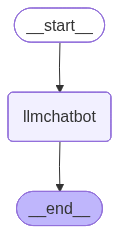

In [63]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception :
    raise Exception

In [64]:
graph.invoke({"messages":["How do you think"]})         

{'messages': [HumanMessage(content='How do you think', additional_kwargs={}, response_metadata={}, id='6955fb1a-7fbc-4574-a959-c61c44e69833')]}


{'messages': [HumanMessage(content='How do you think', additional_kwargs={}, response_metadata={}, id='6955fb1a-7fbc-4574-a959-c61c44e69833'),
  AIMessage(content='I\'m a large language model, so I don\'t think or reason in the same way that humans do. Instead, I use complex algorithms and statistical models to process and generate text.\n\nHere\'s a simplified overview of how I work:\n\n1. **Text Input**: You ask me a question or provide some text, which I use as input.\n2. **Tokenization**: I break down the input text into individual words or tokens, which are then analyzed and processed.\n3. **Part-of-Speech Tagging**: I identify the parts of speech (such as nouns, verbs, adjectives, etc.) for each token, which helps me understand the context and meaning.\n4. **Dependency Parsing**: I analyze the grammatical structure of the sentence, including the relationships between tokens and their dependencies.\n5. **Semantic Role Labeling**: I identify the roles played by entities in a senten

In [65]:
agent=init_chat_model(
    model="groq:llama-3.1-8b-instant"
)

tavily search is a tool

In [66]:
from langchain_tavily import TavilySearch
from langchain.tools import tool

tool1=TavilySearch(max_results=2)
tool1.invoke("How do you think")

{'query': 'How do you think',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://zim.vn/what-do-you-think-va-how-do-you-think',
   'title': 'Phân biệt What do you think và How do you think đơn giản',
   'content': '# Phn biệt cách dùng What do you think và How do you think. “What” là một từ để hỏi thường để khai thác thông tin, sự việc, cái gì…Tuy nhiên “How” thường được dùng để hỏi về trạng thái, cách dùng hay nói cách khác là “như thế nào”. | “What do you think?” là một cu hỏi được dùng để hỏi ý kiến, cảm nghĩ của ai đó về một sự vật/sự việc. “How do you think?” được dùng để hỏi đối phương cách họ nghĩ về một vấn đề như thế nào. ## Phn biệt giữa What và How. What là một từ nghi vấn (Interrogative Determiners) được dịch là “cái gì?” dùng để hỏi thông tin cụ thể về một điều gì đó, có thể là sự việc, hoặc người. Mặt khác thì, “how do you think?” được dùng để hỏi đối phương cách họ nghĩ về một vấn đề như thế nào.',
   'score': 0.81524754,
   'raw_

In [67]:
@tool
def multiply(a:int,b:int)->int:
    ''' Multiply a and b
    _Args:
    a(int): first number
    b(int): second number
    
    Returns:
    description
    '''
    return a*b

combining tools

In [68]:
tools=[tool1,multiply]

Binding tools

In [69]:
agent_with_tools=agent.bind_tools(tools)

### Tool Calling Agent Vs ReAct Agent
-   Tool Calling Agent works like
User
 ->
LLM
 ->
Generate ALL required tool calls
 ->
Execute ALL tool calls
 ->
END


- React Agent works like 

User
 ->
LLM (Reason)
 ->
Tool Call (Act)
 ->
Tool Result (Observe)
 ->
LLM (Reason Again)
 ->
Tool Call?
 ->
Tool Result?
 ->
LLM
 ->
Final Answer

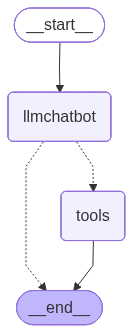

In [ ]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

def llmchatbot(state:State):
    return {"messages":[agent_with_tools.invoke(state["messages"])]}

# tool calling agent 
builder=StateGraph(State)
builder.add_node("llmchatbot",llmchatbot)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,'llmchatbot')
builder.add_conditional_edges(
    'llmchatbot',
    tools_condition  ## tools_condition will decide if it needs to go to ToolNode(tools) or not.
)
builder.add_edge("tools",END)

graph=builder.compile()

builder.compile()



In [71]:
# ReAct Agent
builder=StateGraph(State)
builder.add_node("llmchatbot",llmchatbot)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,'llmchatbot')
builder.add_conditional_edges(
    'llmchatbot',
    tools_condition
)
builder.add_edge("tools","llmchatbot")
builder.add_edge("llmchatbot",END)

graph=builder.compile()

builder.compile

<bound method StateGraph.compile of <langgraph.graph.state.StateGraph object at 0x00000237A631CFE0>>

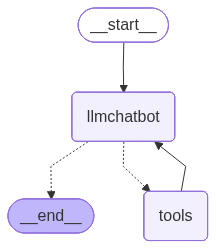

In [72]:
from IPython.display import display,Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [73]:
response=graph.invoke({"messages":["give the recent ai updates and multiply 5*5 & multiply 7*7"]})
response["messages"][2:]

[ToolMessage(content='{"query": "Recent AI updates", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://techcrunch.com/2026/06/04/what-to-expect-from-wwdc-2026-siris-highly-anticipated-revamp-and-apple-intelligence-updates/", "title": "What to expect from WWDC 2026: Siri\'s highly anticipated revamp and Apple Intelligence updates - TechCrunch", "score": 0.9976404, "published_date": "Thu, 04 Jun 2026 16:31:12 GMT", "content": "# What to expect from WWDC 2026: Siri’s highly anticipated revamp and Apple Intelligence updates. As Apple’s Worldwide Developers Conference, WWDC 2026, approaches, the excitement is building around what Apple has in store for us this year. From Siri’s overhaul to new Apple Intelligence updates, there’s a lot to look forward to. For those eager to tune in, the event will be streamed live via the Apple Developer app, Apple’s website, and the Apple Developer YouTube channel. The most anticipated announcement is a major AI upgrade

### Adding memory to chatBot
using library langgraph.checkpointer we will import MemorySaver, this helps in storing context using the config.

In [74]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

graph=builder.compile(checkpointer=memory)


In [75]:
config={'configurable':{'thread_id':'1'}}
response=graph.invoke({'messages':"hi,My name is nitin"}, config=config)
response

{'messages': [HumanMessage(content='hi,My name is nitin', additional_kwargs={}, response_metadata={}, id='ec9b45dc-fc16-48b9-883b-8c1ddce7ed8e'),
  AIMessage(content="It's nice to meet you, Nitin. How can I assist you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 1793, 'total_tokens': 1811, 'completion_time': 0.024286036, 'completion_tokens_details': None, 'prompt_time': 0.190558003, 'prompt_tokens_details': None, 'queue_time': 0.063467256, 'total_time': 0.214844039}, 'model_name': 'llama-3.1-8b-instant', 'system_fingerprint': 'fp_4387d3edbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e965e-9587-72b0-92db-b030020c995b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1793, 'output_tokens': 18, 'total_tokens': 1811})]}

In [76]:
response1=graph.invoke({'messages':"What is my name"}, config=config)
response1

{'messages': [HumanMessage(content='hi,My name is nitin', additional_kwargs={}, response_metadata={}, id='ec9b45dc-fc16-48b9-883b-8c1ddce7ed8e'),
  AIMessage(content="It's nice to meet you, Nitin. How can I assist you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 1793, 'total_tokens': 1811, 'completion_time': 0.024286036, 'completion_tokens_details': None, 'prompt_time': 0.190558003, 'prompt_tokens_details': None, 'queue_time': 0.063467256, 'total_time': 0.214844039}, 'model_name': 'llama-3.1-8b-instant', 'system_fingerprint': 'fp_4387d3edbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e965e-9587-72b0-92db-b030020c995b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1793, 'output_tokens': 18, 'total_tokens': 1811}),
  HumanMessage(content='What is my name', additional_kwargs={}, response_metadata={}, id='eee11096-fd95-432a-ac0e-5